<a href="https://colab.research.google.com/github/varaprasaddalai-afk/Spotify-songs-cohorts/blob/main/Rolling_Stones_Spotify_1_(Dalai's).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Project Title **:

*Rolling Stones Spotify Song Cohort Analysis Using K-Means Clustering*

**Course**:

*Machine Learning*

**Student**: Dalai Siva Durga Venkata Narasimha Vara Prasad.

** Data Used **: *** rolling_stones_spotify.csv ***

** My project roadmap **;

**Create the Colab notebook**

**Upload the Problem Statement**

**Upload the Dictionary**

**Upload the Spotify CSV dataset**

Step 1 — Import Python libraries

Step 2 — Load and inspect the dataset

Step 3 — Understand the columns using the Data Dictionary

Step 4 — Clean the data

Step 5 — Exploratory Data Analysis (EDA)

Step 6 — Select Spotify audio features for clustering

Step 7 — Scale/standardize the features

Step 8 — Find the optimal number of clusters

Step 9 — Apply K-Means clustering

Step 10 — Analyze and interpret the song cohorts

Step 11 — Visualize the clusters

Step 12 — Identify the Key Characteristics of Each Cluster

Step 13 — Cluster Interpretation

Step 14 — Final Cluster Summary

Step 15 — Project Conclusion

Step 16 — Business/Practical Recommendations

** Step1 **: Import the libraries needed

In [1]:
# import required Python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


** Step2 ** — Load and inspect the Spotify dataset;

** Step 2A ** Load rolling_stones_spotify.csv

In [2]:
# Step 2A Load the Spotify dataset

file_path = "/content/rolling_stones_spotify.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset loaded successfully
Number of rows: 1610
Number of columns: 18


** Observation **: The Spotify dataset was loaded successfully into a Pandas DataFrame. The dataset contains 1,610 songs and 18 variables. This confirms that the data has been imported correctly and is ready for further inspection and analysis.

** Step 2B ** — Inspect the first rows


In [3]:
# Step 2B Inspect the first 5 rows

df.head()

,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160
3,3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880
4,4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.303,0.969,0.055900,0.966,-5.098,0.0930,130.533,0.2060,32,305106


** Observation **: The first five records show Spotify tracks with information about the song, album, release date, track number, Spotify identifiers, and several audio features. The dataset contains both descriptive song information and numerical audio characteristics such as acousticness, danceability, and energy. These audio features will be important for creating meaningful song cohorts through clustering. An Unnamed: 0 column is also present and will be examined during data cleaning.

** Step 2C **: Dataset Structure

In [4]:
# Inspect dataset sturcture

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   object 
 2   album             1610 non-null   object 
 3   release_date      1610 non-null   object 
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   object 
 6   uri               1610 non-null   object 
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness          1610 non-null   float64
 12  loudness          1610 non-null   float64
 13  speechiness       1610 non-null   float64
 14  tempo             1610 non-null   float64
 15  valence           1610 non-null   float64
 16  popularity        1610 non-null   int64  


** Observation **: The dataset contains 1,610 songs and 18 variables. All 18 columns have complete records, indicating that there are no missing values at this stage. The dataset contains both categorical/text variables and numerical Spotify audio features. The audio features are stored as floating-point values and will be particularly useful for clustering. The Unnamed: 0 column appears to be an unnecessary saved index and will be removed during data cleaning. The release_date column is currently stored as text and may be converted to a date format if required.

** Step 2D **: Check missing values explicitly

In [5]:
# Step 2D: Check for missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
Unnamed: 0          0
name                0
album               0
release_date        0
track_number        0
id                  0
uri                 0
acousticness        0
danceability        0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
valence             0
popularity          0
duration_ms         0
dtype: int64

Total missing values: 0


** Observation **: The missing-value analysis shows that all 18 variables contain zero missing values. Therefore, no missing-value imputation is required. The dataset is complete and can proceed to the data-cleaning and exploratory-analysis stages.

** Step 3 **: ***Understand the Spotify variables***
Now we need to decide which variables should actually be used for clustering.

We'll examine their distributions and relationships before deciding the final feature set.


** Step 3A **: Display all column names


In [6]:
# Step 3A: Display all column names

print("Columns in the dataset:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")


Columns in the dataset:
1. Unnamed: 0
2. name
3. album
4. release_date
5. track_number
6. id
7. uri
8. acousticness
9. danceability
10. energy
11. instrumentalness
12. liveness
13. loudness
14. speechiness
15. tempo
16. valence
17. popularity
18. duration_ms


** Observation **: The dataset contains 18 variables covering song identification, album and release information, track details, Spotify identifiers, audio characteristics, popularity, and song duration. The *variables acousticness, danceability, energy, instrumentalness, liveness, loudness,* speechiness, tempo, and valence represent important audio characteristics that can be used to describe the musical properties of songs. Variables such as song name, album, Spotify ID, and URI are identifiers or descriptive fields and are not suitable as clustering inputs.

** Step 3B **: Examine the Data Dictionary

In [7]:
# Step 3B: Inspect the Data Dictionary

dictionary_file = "/content/Data Dictionary - Creating cohorts of songs.xlsx"

excel_file = pd.ExcelFile(dictionary_file)

print("Sheets available in the Data Dictionary:")
print(excel_file.sheet_names)

Sheets available in the Data Dictionary:
['Sheet1']


** Step 3C ** — Read the Data Dictionary

In [8]:
# Step 3C: Read the Data Dictionary

data_dictionary = pd.read_excel(dictionary_file, sheet_name="Sheet1")

print("Data Dictionary:")
display(data_dictionary)

Data Dictionary:


,Variable,Description
0,name,the name of the song
1,album,the name of the album
2,release_date,the day month and year the album was released
3,track number,the order the song appears on the album
4,id,the Spotify id for the song
5,uri,the Spotify uri for the song
6,acousticness,A confidence measure from 0.0 to 1.0 of whethe...
7,danceability,Danceability describes how suitable a track is...
8,energy,Energy is a measure from 0.0 to 1.0 and repres...
9,instrumentalness,"Predicts whether a track contains no vocals. ""..."


** Observation **: The Data Dictionary confirms that the dataset contains nine core Spotify audio features that describe the musical characteristics of each song: acousticness, danceability, energy, instrumentalness, liveness, loudness, speechiness, tempo, and valence. These variables are appropriate candidates for clustering because they describe different aspects of the sound and musical character of the tracks. Identification and descriptive variables such as song name, album, Spotify ID, and URI will not be used as clustering inputs.

** Step 3D **: Examine the numerical features

Before we finalize the clustering variables, let's look at their summary statistics.

This will help us understand their ranges and detect anything unusual.

In [9]:
# Step 3D: Summary statistics of numerical variables

numeric_columns = df.select_dtypes(include=np.number).columns

print("Summary statistics:")
display(df[numeric_columns].describe().T)

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1610.0,804.500000,464.911282,0.000000,402.250000,804.50000,1206.75000,1609.000
track_number,1610.0,8.613665,6.560220,1.000000,4.000000,7.00000,11.00000,47.000
acousticness,1610.0,0.250475,0.227397,0.000009,0.058350,0.18300,0.40375,0.994
danceability,1610.0,0.468860,0.141775,0.104000,0.362250,0.45800,0.57800,0.887
energy,1610.0,0.792352,0.179886,0.141000,0.674000,0.84850,0.94500,0.999
instrumentalness,1610.0,0.164170,0.276249,0.000000,0.000219,0.01375,0.17900,0.996
liveness,1610.0,0.491730,0.349100,0.021900,0.153000,0.37950,0.89375,0.998
loudness,1610.0,-6.971615,2.994003,-24.408000,-8.982500,-6.52300,-4.60875,-1.014
speechiness,1610.0,0.069512,0.051631,0.023200,0.036500,0.05120,0.08660,0.624
tempo,1610.0,126.082033,29.233483,46.525000,107.390750,124.40450,142.35575,216.304


** Observation **: The summary statistics show that the Spotify audio features have different distributions and numerical scales. Most audio features are measured between 0 and 1, while loudness is measured in decibels, tempo in beats per minute, and duration in milliseconds. The Unnamed: 0 variable ranges from 0 to 1,609 and represents a saved row index rather than a meaningful song characteristic. These differences in scale indicate that feature standardization will be necessary before applying clustering algorithms.

** Step 4 **: Data Cleaning

The first clear cleaning action is to remove the unnecessary Unnamed: 0 column.

** Step 4A **: Remove the unwanted index.

In [10]:
# Step 4A: Remove the unnecessary index column

df = df.drop(columns=["Unnamed: 0"])

print("Column removed successfully!")
print("New dataset shape:", df.shape)

Column removed successfully!
New dataset shape: (1610, 17)


** Observation **: The Unnamed: 0 column was identified as a saved dataframe index rather than a meaningful song characteristic. It was removed from the dataset. The cleaned dataset now contains 1,610 rows and 17 meaningful variables, with no loss of song records.

** Step 4B **: Check for the Duplicate Songs

In [11]:
# Step 4B: Check for duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


** Observation **: The duplicate-row check identified 0 duplicate records in the dataset. Therefore, no rows need to be removed due to complete duplication. The dataset retains all 1,610 song records for further analysis.

** Step 4C **: Check for duplicate Spotify IDs

In [12]:
# Step 4C: Check for duplicate Spotify IDs

duplicate_ids = df["id"].duplicated().sum()

print("Number of duplicate Spotify IDs:", duplicate_ids)

Number of duplicate Spotify IDs: 0


** Observation **: The Spotify ID check identified 0 duplicate Spotify IDs. This confirms that each record represents a unique Spotify track based on its Spotify identifier. Therefore, no additional records need to be removed for duplicate song IDs.

** Step 5 **: Exploratory Data Analysis (EDA)

** Step 5A **: Distribution of Spotify Audio Features

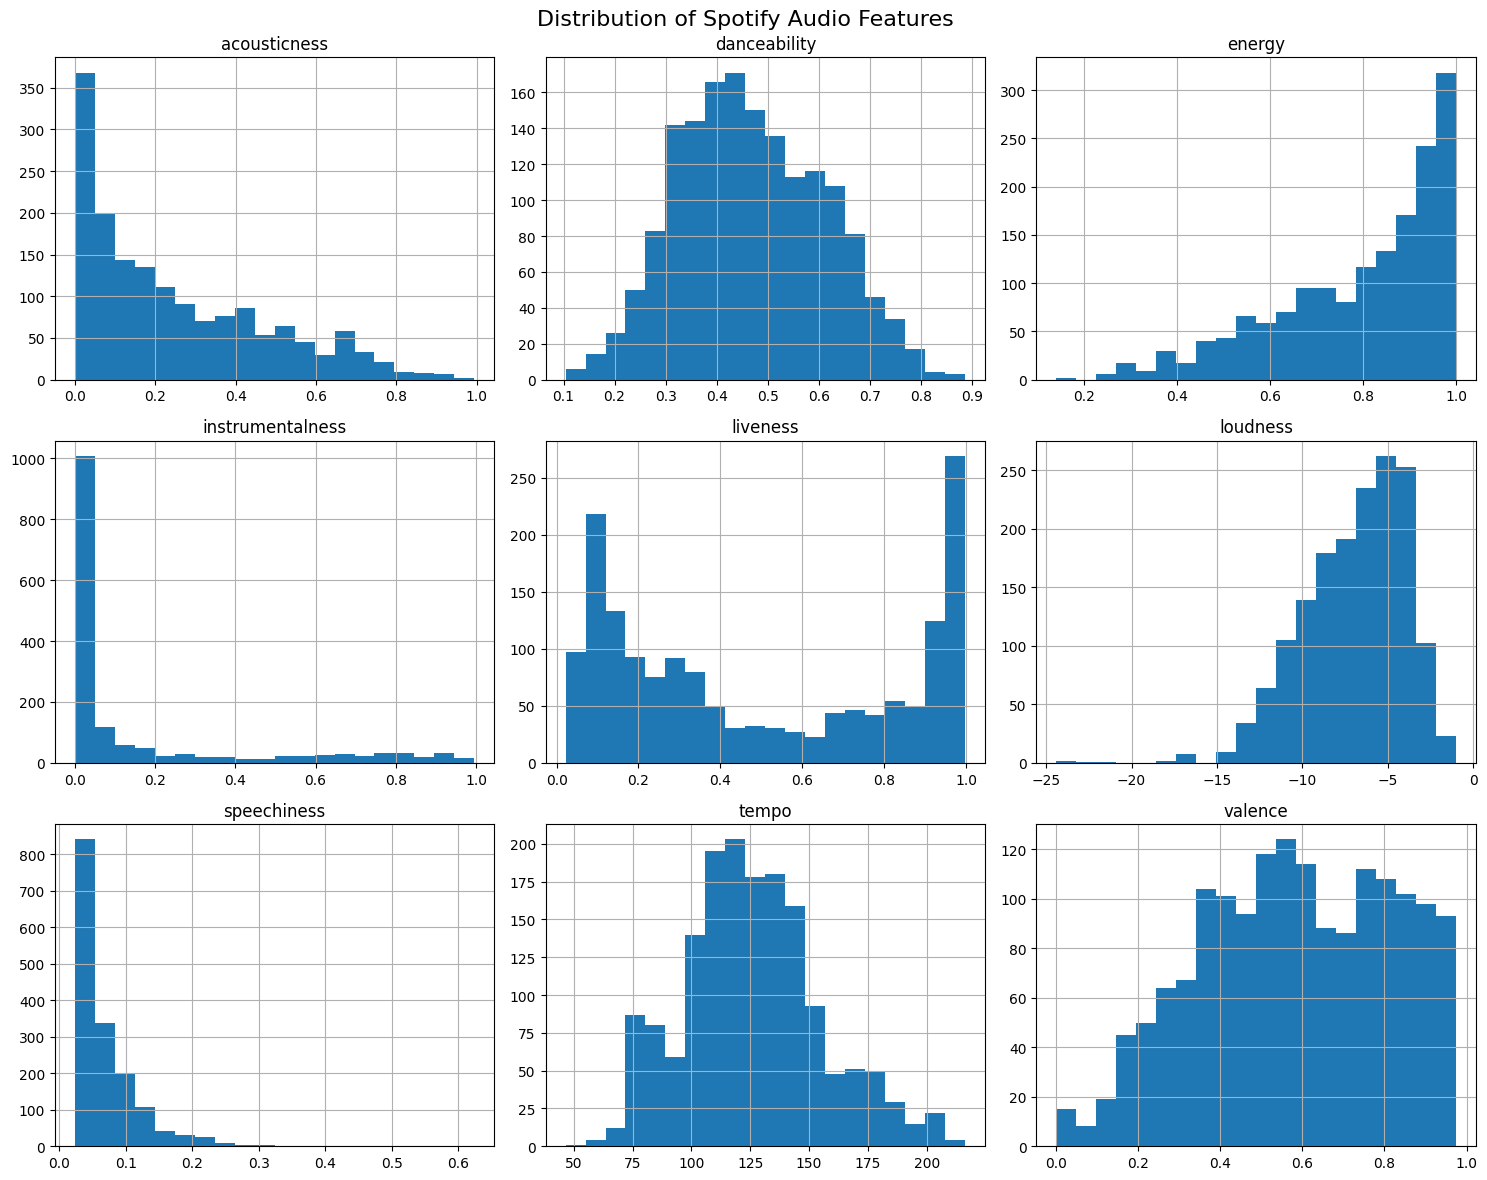

In [13]:
# Step 5A: Distribution of Spotify audio features

audio_features = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence"
]

df[audio_features].hist(
    figsize=(15, 12),
    bins=20
)

plt.suptitle("Distribution of Spotify Audio Features", fontsize=16)
plt.tight_layout()
plt.show()

** Observation **: The distributions of the Spotify audio features show substantial variation across songs. Danceability and valence have relatively broad distributions, while acousticness, instrumentalness, and speechiness are strongly concentrated toward lower values. Energy is concentrated toward higher values, indicating that many songs in the dataset are relatively energetic. Liveness shows concentrations at both lower and higher values, while loudness is mainly concentrated around moderate negative decibel levels. Tempo is broadly distributed, with most songs falling around the 100–150 BPM range. These differences in distribution reinforce the need to standardize the selected features before applying clustering.

** Step 5B ** *italicized text* — Correlation Analysis

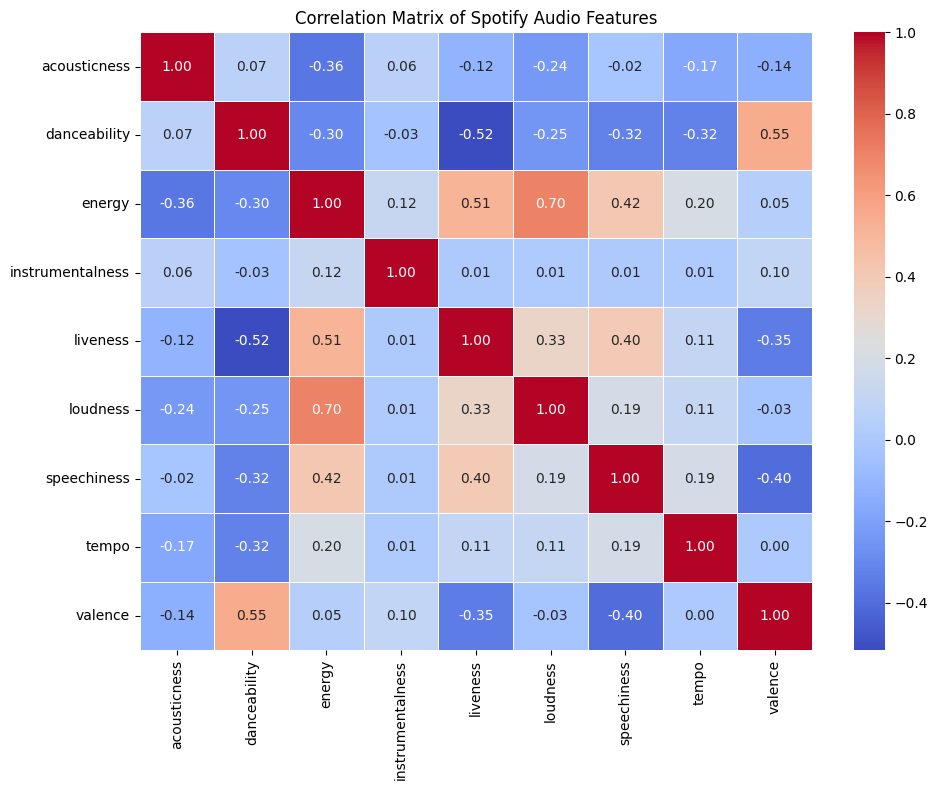

In [14]:
# Step 5B: Correlation matrix of Spotify audio features

correlation_matrix = df[audio_features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Spotify Audio Features")
plt.tight_layout()
plt.show()

** Observation **: The correlation analysis shows that several Spotify audio features have meaningful relationships with each other. Energy has a strong positive correlation with loudness (0.70), indicating that more energetic songs tend to have higher loudness levels. Danceability has a moderate positive correlation with valence (0.55), while danceability has a moderate negative correlation with liveness (-0.52). Energy also shows a moderate positive relationship with liveness (0.51). Acousticness is moderately negatively correlated with energy (-0.36), suggesting that more acoustic songs tend to be less energetic. Overall, the features are not perfectly correlated, indicating that they provide different information about the musical characteristics of songs and are suitable for clustering.

** Step 6 **: Feature Selection for Clustering;

**Step 6A** Select the clustering features


In [15]:
# Step 6A: Select Spotify audio features for clustering

audio_features = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence"
]

# Create the feature dataset
X = df[audio_features].copy()

print("Selected features for clustering:")
for i, feature in enumerate(audio_features, start=1):
    print(f"{i}. {feature}")

print("\nShape of clustering dataset:", X.shape)


Selected features for clustering:
1. acousticness
2. danceability
3. energy
4. instrumentalness
5. liveness
6. loudness
7. speechiness
8. tempo
9. valence

Shape of clustering dataset: (1610, 9)


** Observation **: Nine Spotify audio features were selected for clustering: acousticness, danceability, energy, instrumentalness, liveness, loudness, speechiness, tempo, and valence. These variables directly describe the musical and audio characteristics of each song and are therefore appropriate for creating meaningful song cohorts. Identification and descriptive variables such as song name, album, Spotify ID, URI, release date, and track number were excluded because they do not represent musical similarity. Popularity and duration were also excluded so that the clusters primarily reflect the intrinsic audio characteristics of the songs.

** Step 6B ** Verify the selected features

In [16]:
# Step 6B: Verify the selected clustering features

print("Selected clustering features and data types:")
print(X.dtypes)

print("\nMissing values in selected features:")
print(X.isnull().sum())

print("\nShape of selected feature dataset:", X.shape)

Selected clustering features and data types:
acousticness        float64
danceability        float64
energy              float64
instrumentalness    float64
liveness            float64
loudness            float64
speechiness         float64
tempo               float64
valence             float64
dtype: object

Missing values in selected features:
acousticness        0
danceability        0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
valence             0
dtype: int64

Shape of selected feature dataset: (1610, 9)


** Observation **: The selected clustering dataset contains 1,610 songs and 9 numerical Spotify audio features. All selected variables are stored as float64 data types, confirming that they are suitable for numerical clustering. The missing-value check shows 0 missing values across all nine features, so no additional missing-value treatment is required. The selected feature dataset is therefore complete and ready for the standardization process.

** Step 7 **: Feature Standardization

In [17]:
# Step 7: Standardize the clustering features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Convert the standardized array back to a DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=audio_features
)

print("Standardization completed successfully!")
print("Shape of standardized dataset:", X_scaled_df.shape)

print("\nMean of standardized features:")
print(X_scaled_df.mean().round(2))

print("\nStandard deviation of standardized features:")
print(X_scaled_df.std().round(2))

Standardization completed successfully!
Shape of standardized dataset: (1610, 9)

Mean of standardized features:
acousticness       -0.0
danceability       -0.0
energy              0.0
instrumentalness    0.0
liveness            0.0
loudness           -0.0
speechiness        -0.0
tempo               0.0
valence             0.0
dtype: float64

Standard deviation of standardized features:
acousticness        1.0
danceability        1.0
energy              1.0
instrumentalness    1.0
liveness            1.0
loudness            1.0
speechiness         1.0
tempo               1.0
valence             1.0
dtype: float64


** Observation **: The nine selected Spotify audio features were standardized using StandardScaler. After standardization, each feature has a mean approximately equal to 0 and a standard deviation equal to 1. This ensures that variables measured on different scales, such as loudness and tempo, do not disproportionately influence the clustering process. The standardized dataset contains 1,610 songs and 9 features and is ready for determining the optimal number of clusters.

** Step 8 **: Find the Optimal Numbers of Clusters

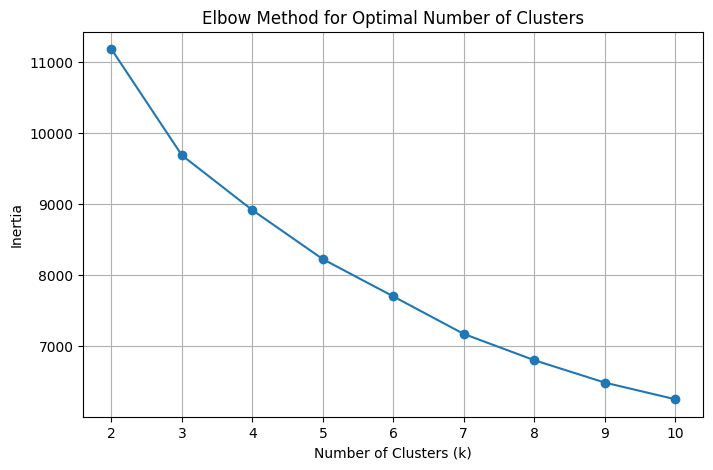

In [18]:
# Step 8A: Determuine the optimal numbers of clusters by using the Elbow Method

inertia = []

# Test cluster sizes from 2 to 10
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled_df)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal Number of Clusters")

plt.xticks(k_values)
plt.grid(True)
plt.show()

** Observation **: The Elbow Method was used to determine the optimal number of clusters by examining the reduction in within-cluster inertia. The inertia decreases sharply as the number of clusters increases from 2 to 4, after which the rate of improvement becomes more gradual. The elbow is therefore observed around k = 4, suggesting that four clusters provide a suitable balance between cluster compactness and model simplicity. This value will be further evaluated using the Silhouette Score.

** Step 8B **: Find out the Silhouette Score

Silhouette Scores:
k = 2: 0.2149
k = 3: 0.1896
k = 4: 0.1854
k = 5: 0.1599
k = 6: 0.1537
k = 7: 0.1653
k = 8: 0.1718
k = 9: 0.1753
k = 10: 0.1767


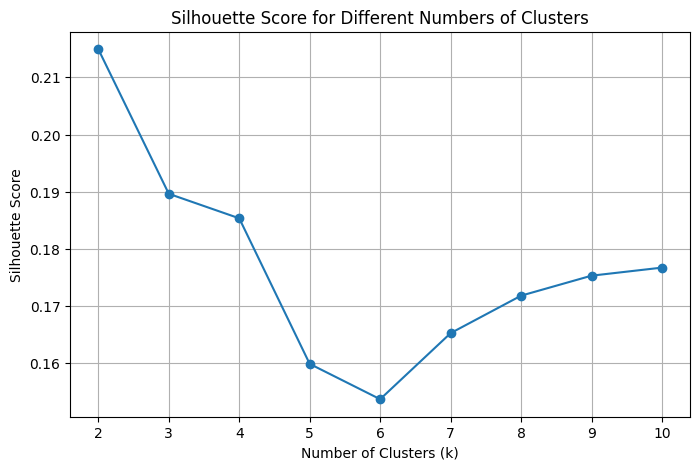

In [19]:
# Step 8B: Evaluate clustering quality using Silhouette Score

silhouette_scores = []

# Test cluster sizes from 2 to 10
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled_df)

    score = silhouette_score(X_scaled_df, cluster_labels)
    silhouette_scores.append(score)

# Display the scores
print("Silhouette Scores:")

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"k = {k}: {score:.4f}")

# Plot the Silhouette Scores
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different Numbers of Clusters")

plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

** Observation **: The Silhouette Score was calculated for cluster sizes ranging from 2 to 10. The highest Silhouette Score is 0.2149 at k = 2, indicating that two clusters provide the best separation and cohesion among the tested solutions. Although the Elbow Method suggested an elbow around k = 4, the Silhouette analysis favors k = 2. Considering both evaluation methods, k = 2 is selected as the final number of clusters because it provides the strongest overall cluster separation according to the Silhouette Score.

** Step 9 **: Apply K-Means Clustering;

** Step 9A **: Apply K-Means with 2 Clusters

In [20]:
# Step 9A: Apply K-Means clustering with the selected number of clusters

# Set the optimal number of clusters
optimal_k = 2

# Create and fit the K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Assign each song to a cluster
cluster_labels = kmeans.fit_predict(X_scaled_df)

# Add cluster labels to the original dataframe
df["cluster"] = cluster_labels

print("K-Means clustering completed successfully!")
print("Number of clusters:", optimal_k)

print("\nNumber of songs in each cluster:")
print(df["cluster"].value_counts().sort_index())

K-Means clustering completed successfully!
Number of clusters: 2

Number of songs in each cluster:
cluster
0    709
1    901
Name: count, dtype: int64


** Step 9B **: **Observation**;
K-Means clustering was successfully applied using the selected value of k = 2. The 1,610 songs were divided into two song cohorts: Cluster 0 contains 709 songs and Cluster 1 contains 901 songs. Both clusters contain a substantial number of songs, indicating that the clustering produced two meaningful groups rather than an extremely imbalanced solution. The next step is to compare the audio-feature profiles of the two clusters to understand their musical characteristics.

** Step 9C **: Compare the two clusters

In [21]:
# Step 9C: Compare the average audio features of the two clusters

cluster_profile = df.groupby("cluster")[audio_features].mean()

print("Average audio feature values by cluster:")
display(cluster_profile.round(3))

Average audio feature values by cluster:


,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
cluster,,,,,,,,,
0,0.190,0.371,0.916,0.158,0.792,-5.445,0.098,135.766,0.483
1,0.298,0.546,0.695,0.169,0.256,-8.173,0.047,118.462,0.660


** Step 9D **: **Observation**;
The average audio-feature profiles show clear differences between the two song clusters. Cluster 0, containing 709 songs, has higher energy (0.916), liveness (0.792), loudness (-5.445 dB), tempo (135.766 BPM), and speechiness (0.098). It has lower danceability (0.371), acousticness (0.190), and valence (0.483). Cluster 1, containing 901 songs, has higher danceability (0.546), acousticness (0.298), and valence (0.660), but lower energy (0.695), liveness (0.256), loudness (-8.173 dB), tempo (118.462 BPM), and speechiness (0.047). Overall, Cluster 0 represents higher-energy, faster, louder, and more live-oriented songs, while Cluster 1 represents more danceable, acoustic, positive-valence, and comparatively calmer songs.

** Step 9E **: Visulizition of cluster profiles

<Figure size 1200x600 with 0 Axes>

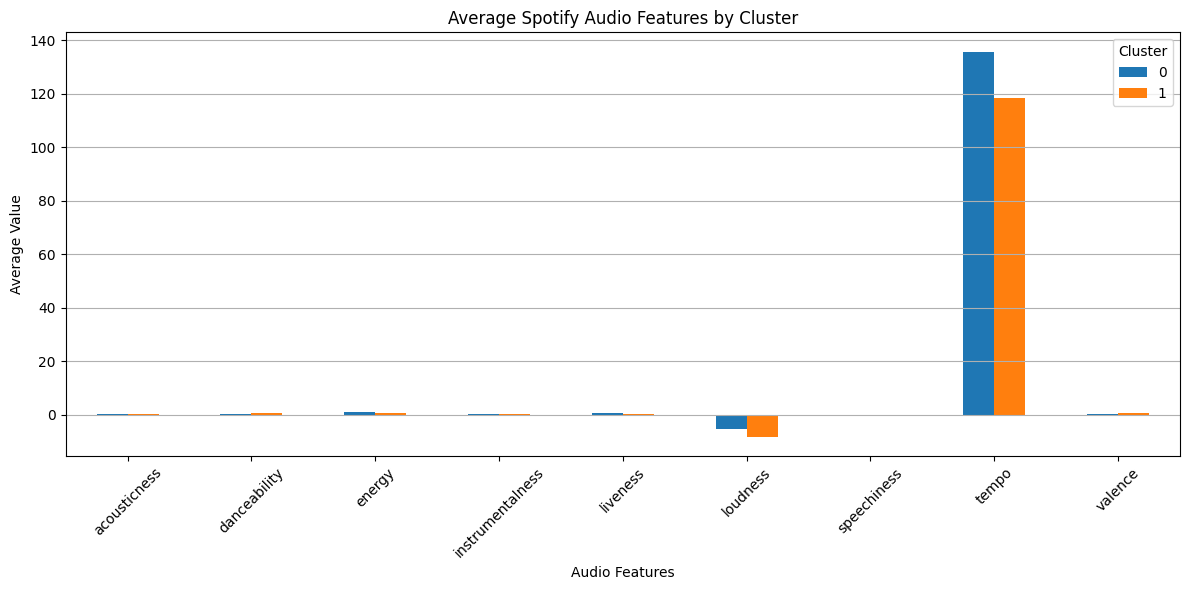

In [22]:
# Step 9E: Visualize the average audio features of the clusters

plt.figure(figsize=(12, 6))

cluster_profile.T.plot(kind="bar", figsize=(12, 6))

plt.title("Average Spotify Audio Features by Cluster")
plt.xlabel("Audio Features")
plt.ylabel("Average Value")
plt.xticks(rotation=45)
plt.legend(title="Cluster")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

** Step 9F **: **Observation**;
The cluster-profile visualization confirms that the two song cohorts have distinct audio characteristics. Cluster 0 is characterized by higher energy, liveness, loudness, and tempo, indicating a more energetic and live-oriented musical profile. Cluster 1 shows higher danceability, acousticness, and valence, suggesting comparatively more danceable, acoustic, and positive-sounding songs. The visualization therefore supports the conclusion that K-Means has identified two interpretable song cohorts based on their audio characteristics.

** Step 10 **: Detailed Cluster Analysis

In [23]:
# Step 10A: Create a summary of the song cohorts

cluster_summary = df.groupby("cluster").agg(
    song_count=("name", "count"),
    avg_energy=("energy", "mean"),
    avg_danceability=("danceability", "mean"),
    avg_acousticness=("acousticness", "mean"),
    avg_liveness=("liveness", "mean"),
    avg_loudness=("loudness", "mean"),
    avg_tempo=("tempo", "mean"),
    avg_valence=("valence", "mean"),
    avg_speechiness=("speechiness", "mean")
)

print("Song Cohort Summary:")
display(cluster_summary.round(3))

Song Cohort Summary:


,song_count,avg_energy,avg_danceability,avg_acousticness,avg_liveness,avg_loudness,avg_tempo,avg_valence,avg_speechiness
cluster,,,,,,,,,
0,709,0.916,0.371,0.190,0.792,-5.445,135.766,0.483,0.098
1,901,0.695,0.546,0.298,0.256,-8.173,118.462,0.660,0.047


** Step 10B **: **Observation**;
The detailed cohort analysis confirms that the two clusters have distinct musical profiles. Cluster 0 contains 709 songs and is characterized by very high energy (0.916), high liveness (0.792), higher loudness (-5.445 dB), and faster tempo (135.766 BPM). Its danceability (0.371) and valence (0.483) are comparatively lower. Cluster 1 contains 901 songs and has lower energy (0.695), much lower liveness (0.256), lower loudness (-8.173 dB), and slower tempo (118.462 BPM). It has higher danceability (0.546), acousticness (0.298), and valence (0.660). Therefore, Cluster 0 can be interpreted as a high-energy/live-oriented cohort, while Cluster 1 can be interpreted as a more danceable, acoustic, and positive-sounding cohort.

** Step 10C **: Find the representative songs

In [24]:
# Step 10C: Display representative songs from each cluster

for cluster in sorted(df["cluster"].unique()):
    print(f"\nCluster {cluster} - Sample Songs")

    sample_songs = df[df["cluster"] == cluster][
        ["name", "album", "release_date", "energy",
         "danceability", "acousticness", "liveness",
         "loudness", "tempo", "valence"]
    ].head(10)

    display(sample_songs)


Cluster 0 - Sample Songs


,name,album,release_date,energy,danceability,acousticness,liveness,loudness,tempo,valence
0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,0.993,0.463,0.0824,0.932,-12.913,118.001,0.0302
1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,0.965,0.326,0.4370,0.961,-4.803,131.455,0.3180
2,Start Me Up - Live,Licked Live In NYC,2022-06-10,0.969,0.386,0.4160,0.956,-4.936,130.066,0.3130
3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,0.985,0.369,0.5670,0.895,-5.535,132.994,0.1470
4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,0.969,0.303,0.4000,0.966,-5.098,130.533,0.2060
5,Monkey Man - Live,Licked Live In NYC,2022-06-10,0.956,0.340,0.2750,0.741,-5.539,101.628,0.1250
6,Angie - Live,Licked Live In NYC,2022-06-10,0.810,0.262,0.5610,0.972,-6.851,77.520,0.3940
7,Let It Bleed - Live,Licked Live In NYC,2022-06-10,0.971,0.413,0.3170,0.993,-5.509,128.958,0.4840
8,Midnight Rambler - Live,Licked Live In NYC,2022-06-10,0.942,0.268,0.4160,0.959,-6.018,139.452,0.2850
9,Tumbling Dice - Live,Licked Live In NYC,2022-06-10,0.944,0.310,0.4010,0.974,-5.074,119.782,0.1880



Cluster 1 - Sample Songs


,name,album,release_date,energy,danceability,acousticness,liveness,loudness,tempo,valence
30,Crackin’ Up - Live At The El Mocambo 1977,Live At The El Mocambo,2022-05-13,0.801,0.594,0.3080,0.6990,-7.448,105.572,0.925
33,Tumbling Dice - Live At The El Mocambo 1977,Live At The El Mocambo,2022-05-13,0.842,0.450,0.1330,0.7580,-7.254,107.825,0.768
37,Worried Life Blues - Live At The El Mocambo 1977,Live At The El Mocambo,2022-05-13,0.677,0.417,0.2390,0.7590,-8.309,111.718,0.589
38,Little Red Rooster - Live At The El Mocambo 1977,Live At The El Mocambo,2022-05-13,0.608,0.292,0.1940,0.7460,-8.809,98.803,0.430
43,Melody - Live At The El Mocambo 1977,Live At The El Mocambo,2022-05-13,0.727,0.494,0.4970,0.8940,-7.673,126.323,0.729
44,Luxury - Live At The El Mocambo 1977,Live At The El Mocambo,2022-05-13,0.789,0.568,0.1260,0.7280,-6.731,127.512,0.946
45,Worried About You - Live At The El Mocambo 1977,Live At The El Mocambo,2022-05-13,0.717,0.389,0.5110,0.7140,-6.576,82.795,0.633
46,Start Me Up - Remastered 2021,Tattoo You (Super Deluxe),2021-10-22,0.956,0.555,0.0302,0.0753,-2.147,121.752,0.933
48,Slave - Remastered 2021,Tattoo You (Super Deluxe),2021-10-22,0.898,0.558,0.1300,0.0562,-4.314,133.338,0.853
52,Worried About You - Remastered 2021,Tattoo You (Super Deluxe),2021-10-22,0.714,0.423,0.0804,0.0820,-4.010,84.351,0.383


** Step 10D **: **Observation**;
The sample songs demonstrate that the two clusters contain songs with different audio profiles. The songs assigned to Cluster 0 generally exhibit higher energy, liveness, loudness, and tempo, consistent with a more energetic and performance-oriented cohort. Cluster 1 contains songs with comparatively higher danceability and valence and lower average energy, liveness, and tempo. The sample records therefore provide practical examples supporting the statistical differences identified in the cluster profiles.

** Step 10E **: Cluster size visualization

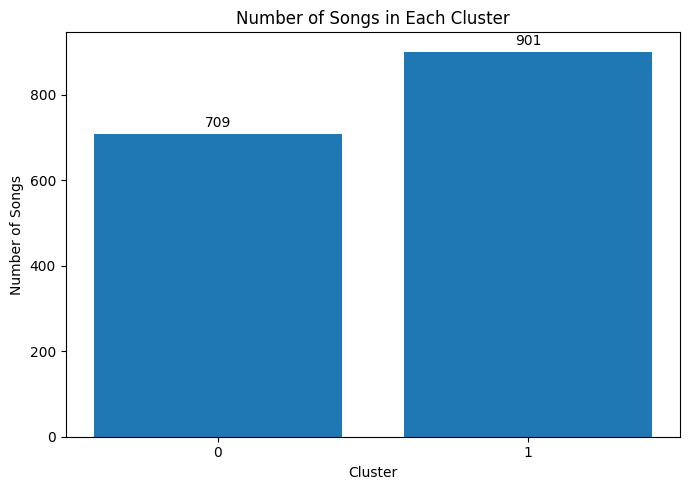

In [25]:
# Step 10E: Visualize the number of songs in each cluster

cluster_counts = df["cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values
)

plt.xlabel("Cluster")
plt.ylabel("Number of Songs")
plt.title("Number of Songs in Each Cluster")

# Display values on top of the bars
for i, value in enumerate(cluster_counts.values):
    plt.text(i, value + 15, str(value), ha="center")

plt.tight_layout()
plt.show()

** Step 10F **: **Observation**;
The cluster-size analysis shows that Cluster 0 contains 709 songs, while Cluster 1 contains 901 songs. Although Cluster 1 is larger, both clusters contain a substantial number of songs, indicating that the K-Means algorithm produced two reasonably sized song cohorts rather than an extremely imbalanced clustering solution.

** Step 11 ** Cluster Visualization

** Step 11A **: PCA for Cluster Visualization

Explained variance by principal components:
PC1: 0.324
PC2: 0.179
Total explained variance: 0.504


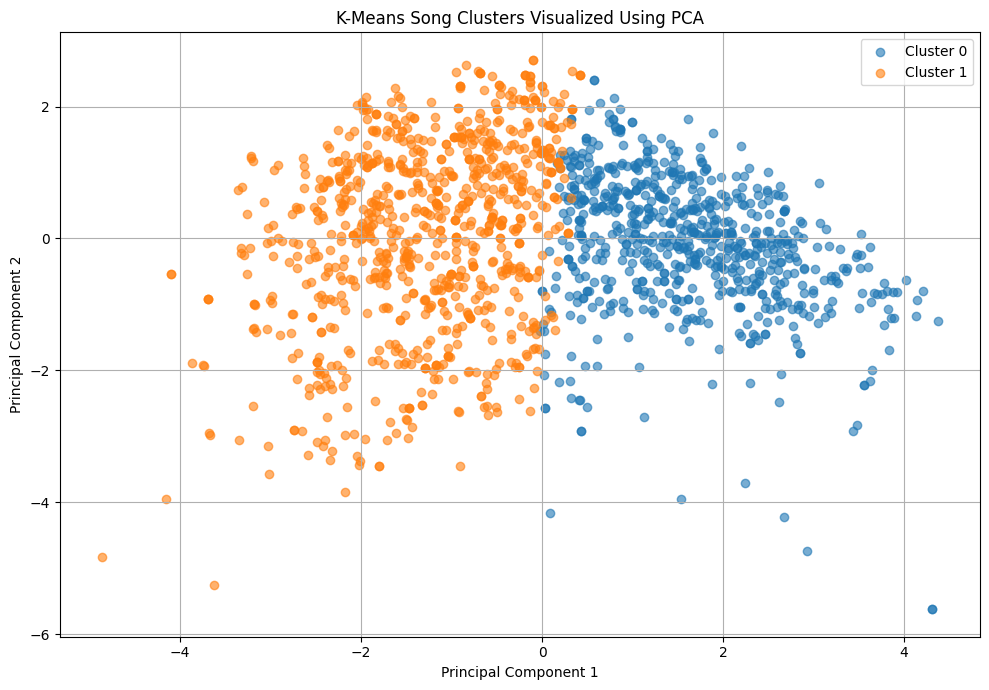

In [26]:
# Step 11A: Visualize the clusters using PCA

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce the standardized features to 2 principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled_df)

# Create a dataframe for visualization
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

# Add cluster labels
pca_df["cluster"] = df["cluster"].values

print("Explained variance by principal components:")
print("PC1:", round(pca.explained_variance_ratio_[0], 3))
print("PC2:", round(pca.explained_variance_ratio_[1], 3))
print("Total explained variance:",
      round(pca.explained_variance_ratio_.sum(), 3))

# Plot the clusters
plt.figure(figsize=(10, 7))

for cluster in sorted(pca_df["cluster"].unique()):
    cluster_data = pca_df[pca_df["cluster"] == cluster]

    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Song Clusters Visualized Using PCA")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

** Step 11B **: **Observation**
PCA was used to visualize the two K-Means clusters in a two-dimensional space. The first principal component explains 32.4% of the total variance, while the second explains 17.9%, giving a combined explained variance of 50.4%. The scatter plot shows a clear separation between Cluster 0 and Cluster 1, particularly along the first principal component. This indicates that the two song cohorts have distinct overall audio-feature profiles.

** Step 12 **: Identify the Key Characteristics of Each Cluster

In [27]:
# Step 12A: Calculate differences between the two clusters

# Calculate the average audio features for each cluster
cluster_means = df.groupby("cluster")[audio_features].mean()

# Calculate the absolute difference between Cluster 0 and Cluster 1
cluster_difference = (
    cluster_means.loc[0] - cluster_means.loc[1]
).abs().sort_values(ascending=False)

print("Audio features ranked by difference between clusters:")
display(cluster_difference.round(3))

Audio features ranked by difference between clusters:


,0
tempo,17.304
loudness,2.729
liveness,0.536
energy,0.221
valence,0.178
danceability,0.174
acousticness,0.108
speechiness,0.051
instrumentalness,0.011


** Step 12B **: **Observation**;

The comparison of cluster averages shows that tempo, loudness, liveness, energy, valence, and danceability are the main features differentiating the two song cohorts. Tempo has the largest difference between the clusters, followed by loudness and liveness. Energy, valence, and danceability also show meaningful differences. In contrast, instrumentalness and speechiness have very small differences, indicating that these features contribute less to distinguishing the two clusters.

** Step 12C **: Visualize the Feature Differences

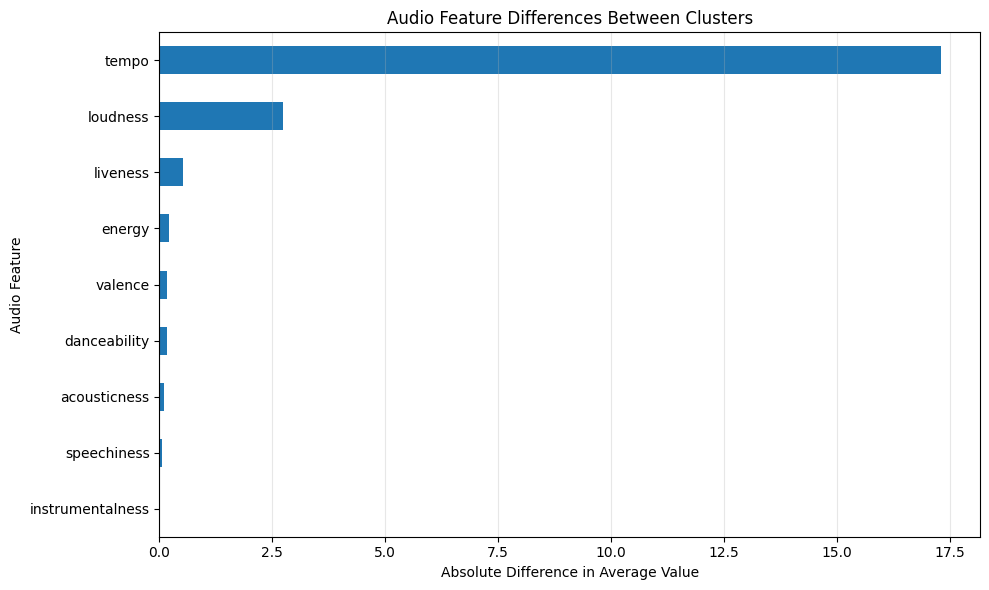

In [28]:
# Step 12C: Visualize the differences between clusters

plt.figure(figsize=(10, 6))

cluster_difference.sort_values().plot(
    kind="barh"
)

plt.xlabel("Absolute Difference in Average Value")
plt.ylabel("Audio Feature")
plt.title("Audio Feature Differences Between Clusters")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

** Step 12D **: **Final Observation**;
The feature-difference chart confirms that tempo is the dominant characteristic separating the two clusters, with a difference of approximately 17.3 BPM. Loudness and liveness are the next most important differentiating features. Energy, valence, danceability, and acousticness show smaller differences, while speechiness and instrumentalness contribute very little to the separation. Therefore, the clusters can primarily be distinguished by differences in tempo, loudness, and liveness.

** Step 13 **:— Cluster Interpretation
The two clusters meaningful descriptions based on the average values calculated.

Cluster 0 – High-Energy and Lively Songs: Cluster 0 contains 709 songs. These songs have higher average energy (0.916), liveness (0.792), loudness (-5.445 dB), and tempo (135.766 BPM). They can therefore be characterized as energetic, lively, louder, and faster-paced songs.
Cluster 1 – More Danceable and Positive Songs: Cluster 1 contains 901 songs. These songs have higher average danceability (0.546), valence (0.660), and acousticness (0.298), but lower energy (0.695), liveness (0.256), loudness (-8.173 dB), and tempo (118.462 BPM). They can therefore be characterized as more danceable, positive, relatively less energetic, and slower-paced songs.

** Step 14 **: Final Cluster Summary

In [29]:
# Step 14A: Final cluster summary

final_cluster_summary = df.groupby("cluster").agg(
    song_count=("name", "count"),
    avg_energy=("energy", "mean"),
    avg_danceability=("danceability", "mean"),
    avg_acousticness=("acousticness", "mean"),
    avg_liveness=("liveness", "mean"),
    avg_loudness=("loudness", "mean"),
    avg_tempo=("tempo", "mean"),
    avg_valence=("valence", "mean"),
    avg_speechiness=("speechiness", "mean")
)

print("Final Cluster Summary:")
display(final_cluster_summary.round(3))

Final Cluster Summary:


,song_count,avg_energy,avg_danceability,avg_acousticness,avg_liveness,avg_loudness,avg_tempo,avg_valence,avg_speechiness
cluster,,,,,,,,,
0,709,0.916,0.371,0.190,0.792,-5.445,135.766,0.483,0.098
1,901,0.695,0.546,0.298,0.256,-8.173,118.462,0.660,0.047


** Step 14B **: **Final Observation**;
The final cluster summary confirms that the 1,610 songs were successfully divided into two distinct cohorts. Cluster 0 contains 709 songs and is characterized by higher energy, liveness, loudness, and tempo. Cluster 1 contains 901 songs and is characterized by higher danceability, valence, and acousticness. These differences demonstrate that K-Means clustering successfully identified meaningful groups based on the intrinsic audio characteristics of the songs.

**The final clustering results are consistent**:
- Cluster 0: 709 songs
- Cluster 1: 901 songs
- Total: 1,610 songs
- Cluster 0: higher energy, liveness, loudness, and tempo
- Cluster 1: higher danceability, valence, and acousticness

** Step 15 **: ***Project Conclusion***

The analysis successfully segmented 1,610 Rolling Stones songs into two meaningful cohorts using K-Means clustering based on nine Spotify audio features. Data cleaning removed the unnecessary index column, while duplicate checks confirmed that there were no duplicate records or duplicate Spotify IDs. Exploratory analysis showed substantial variation across the audio features, making standardization necessary before clustering.
The Elbow Method and Silhouette Analysis were used to evaluate the appropriate number of clusters, and k = 2 was selected for the final K-Means model. The resulting clusters contained 709 and 901 songs respectively, indicating a reasonably balanced segmentation.
Cluster 0 represents a group of more energetic, lively, louder, and faster-paced songs, whereas Cluster 1 represents songs with higher danceability, valence, and acousticness and comparatively lower energy, liveness, loudness, and tempo. PCA visualization also showed a clear separation between the two cohorts.
Overall, the clustering analysis demonstrates that unsupervised machine learning can effectively identify meaningful song groups based on intrinsic audio characteristics. These cohorts can be useful for music profiling, playlist organization, recommendation strategies, and further analysis of listener preferences.

** Step 16 **: Business/Practical Recommendations

Step 16 — Recommendations
1. Playlist creation: Create separate playlists based on the characteristics of the two clusters, such as high-energy/faster songs and more danceable/positive songs.
2. Music recommendation: Use the cluster assignments to recommend songs with similar audio profiles.
3. Mood-based organization: Cluster 0 can be useful for energetic or high-intensity listening, while Cluster 1 can support more positive and dance-oriented listening experiences.
4. Further analysis: Future work can examine how song popularity, release period, albums, and other metadata vary across the identified clusters.
5. Model improvement: Additional clustering algorithms such as hierarchical clustering or DBSCAN can be evaluated to determine whether they reveal additional song cohorts.